In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import Ridge
from sklearn.model_selection import train_test_split

In [4]:
# 1. 데이터 준비
arr = np.load('/content/drive/MyDrive/운영/MBC/데이터분석_1기/수업/04_ML/data/boston.npz')
x = arr['x']
y = arr['y']
print(x.shape)
print(y.shape)

(506, 104)
(506,)


In [5]:
# 2. 데이터 나누기
x_train, x_test, y_train, y_test = train_test_split(x,y,random_state=23)

# 3. 알고리즘선택, 학습
# 일반 선형회귀 알고리즘은 변수값이 많을경우
# 전반적으로 가중치를 크게 적용해 과대적합이 일어나기 쉽다.
# 그래서 Ridge 는 alpha 값을 적용해 가중치들을 0에 가깝게 설정할 수 있다.
# 이것을 우리는 L2 규제라 부른다.
# alpha 값은 기본이 1 이다.
model = Ridge(alpha = 1).fit(x_train,y_train)

#4. 결과 보기
print(f'train : {model.score(x_train,y_train)}')
print(f'test : {model.score(x_test,y_test)}')

train : 0.8697104280837328
test : 0.8110814052141841


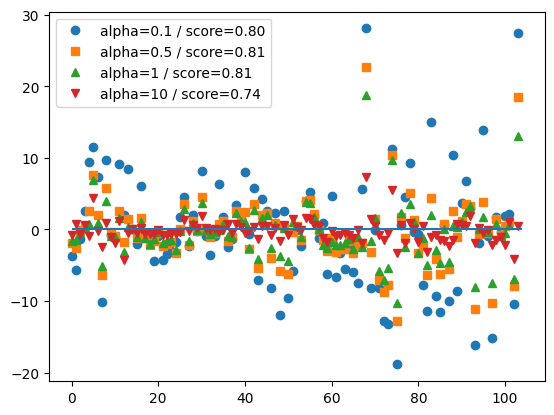

In [6]:
# alpha 값에 따른 가중치 조절
alphas = [0.1,0.5,1,10]

for a,m in zip(alphas,['o','s','^','v']):
  model = Ridge(alpha = a).fit(x_train,y_train)
  score = model.score(x_test,y_test)
  plt.plot(model.coef_, m, label=f'alpha={a} / score={score:.2f}')

plt.hlines(0,0,len(model.coef_))
plt.legend()
plt.show()